In [1]:
import pandas as pd
import numpy as np

df_base = pd.read_csv('data/processed_data_base.csv')
df = pd.read_csv('data/processed_data.csv')

In [2]:
df.head()

,age,default,balance,housing,loan,day,duration,campaign,pdays,previous,...,month_may,month_nov,month_oct,month_sep,pre_contact,age_group_26-35,age_group_36-45,age_group_46-55,age_group_56-65,age_group_65+
0,58,0,7.670429,1,0,5,261,0.693147,0.0,0.0,...,True,False,False,False,0,False,False,False,True,False
1,44,0,3.401197,1,0,5,151,0.693147,0.0,0.0,...,True,False,False,False,0,False,True,False,False,False
2,33,0,1.098612,1,1,5,76,0.693147,0.0,0.0,...,True,False,False,False,0,True,False,False,False,False
3,47,0,7.317876,1,0,5,92,0.693147,0.0,0.0,...,True,False,False,False,0,False,False,True,False,False
4,33,0,0.693147,0,0,5,198,0.693147,0.0,0.0,...,True,False,False,False,0,True,False,False,False,False


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 49 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  45211 non-null  int64  
 1   default              45211 non-null  int64  
 2   balance              45211 non-null  float64
 3   housing              45211 non-null  int64  
 4   loan                 45211 non-null  int64  
 5   day                  45211 non-null  int64  
 6   duration             45211 non-null  int64  
 7   campaign             45211 non-null  float64
 8   pdays                45211 non-null  float64
 9   previous             45211 non-null  float64
 10  y                    45211 non-null  int64  
 11  job_blue-collar      45211 non-null  bool   
 12  job_entrepreneur     45211 non-null  bool   
 13  job_housemaid        45211 non-null  bool   
 14  job_management       45211 non-null  bool   
 15  job_retired          45211 non-null  bool   
 1

In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    f1_score,
    precision_recall_curve,
    average_precision_score
)

import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# K 折交叉验证保持正负类比例
k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scoring = {'F1': 'f1', 'PR-AUC': 'average_precision'}

# 1. baseline

In [5]:
# 基线模型：原始特征 + 类别加权逻辑回归
X_base = df_base.drop(['y', 'duration'], axis=1)
y_base = df_base['y']

X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(
    X_base, y_base, test_size=0.2, stratify=y_base, random_state=42
)

baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        tol=1e-4,
        class_weight='balanced',
        random_state=42
    )
)

baseline_cv = cross_validate(
    baseline_model,
    X_train_base,
    y_train_base,
    cv=k_fold,
    scoring=cv_scoring,
    return_train_score=False,
    n_jobs=-1
)
baseline_model.fit(X_train_base, y_train_base)
y_base_prob = baseline_model.predict_proba(X_test_base)[:, 1]
y_base_pred = baseline_model.predict(X_test_base)

baseline_results = {
    '模型': '基线-逻辑回归（类别加权）',
    'F1': f1_score(y_test_base, y_base_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test_base, y_base_prob),
    'CV F1均值': baseline_cv['test_F1'].mean(),
    'CV PR-AUC均值': baseline_cv['test_PR-AUC'].mean()
}

print('基线模型评估：')
display(pd.DataFrame([baseline_results]).round(4))

基线模型评估：


,模型,F1,PR-AUC,CV F1均值,CV PR-AUC均值
0,基线-逻辑回归（类别加权）,0.3737,0.4092,0.3731,0.3981


# 2. 特征工程效果

In [6]:
# 特征工程后的数据集
X = df.drop(['y', 'duration'], axis=1)
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 类别不平衡：用训练集负类/正类比例设置正类权重
class_counts = y_train.value_counts()
positive_weight = class_counts[0] / class_counts[1]
print(f'训练集负类/正类 = {positive_weight:.2f}')

test_probabilities = {'基线-逻辑回归（类别加权）': (y_test_base, y_base_prob)}
model_results = [baseline_results]
fitted_models = {}

训练集负类/正类 = 7.55


In [7]:
# 逻辑回归
engineered_lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        tol=1e-4,
        class_weight='balanced',
        random_state=42
    )
)
lr_cv = cross_validate(
    engineered_lr_model, X_train, y_train,
    cv=k_fold, scoring=cv_scoring,
    return_train_score=False, n_jobs=-1
)
engineered_lr_model.fit(X_train, y_train)
lr_prob = engineered_lr_model.predict_proba(X_test)[:, 1]
lr_pred = engineered_lr_model.predict(X_test)
lr_result = {
    '模型': '特征工程-逻辑回归',
    'F1': f1_score(y_test, lr_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, lr_prob),
    'CV F1均值': lr_cv['test_F1'].mean(),
    'CV PR-AUC均值': lr_cv['test_PR-AUC'].mean()
}
test_probabilities['特征工程-逻辑回归'] = (y_test, lr_prob)
model_results.append(lr_result)
fitted_models['特征工程-逻辑回归'] = engineered_lr_model
display(pd.DataFrame([lr_result]).round(4))

,模型,F1,PR-AUC,CV F1均值,CV PR-AUC均值
0,特征工程-逻辑回归,0.3901,0.4144,0.381,0.4039


In [8]:
# 随机森林
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)
rf_cv = cross_validate(
    rf_model, X_train, y_train,
    cv=k_fold, scoring=cv_scoring,
    return_train_score=False, n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_prob = rf_model.predict_proba(X_test)[:, 1]
rf_pred = rf_model.predict(X_test)
rf_result = {
    '模型': '特征工程-随机森林',
    'F1': f1_score(y_test, rf_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, rf_prob),
    'CV F1均值': rf_cv['test_F1'].mean(),
    'CV PR-AUC均值': rf_cv['test_PR-AUC'].mean()
}
test_probabilities['特征工程-随机森林'] = (y_test, rf_prob)
model_results.append(rf_result)
fitted_models['特征工程-随机森林'] = rf_model
display(pd.DataFrame([rf_result]).round(4))

,模型,F1,PR-AUC,CV F1均值,CV PR-AUC均值
0,特征工程-随机森林,0.2971,0.4212,0.2956,0.4122


In [9]:
# 梯度提升树：验证集指标连续多轮无提升时提前停止
gb_model = GradientBoostingClassifier(
    random_state=42,
    n_iter_no_change=10,
    validation_fraction=0.1,
    tol=1e-4
)
gb_cv = cross_validate(
    gb_model, X_train, y_train,
    cv=k_fold, scoring=cv_scoring,
    return_train_score=False, n_jobs=-1
)
gb_model.fit(X_train, y_train)
gb_prob = gb_model.predict_proba(X_test)[:, 1]
gb_pred = gb_model.predict(X_test)
gb_result = {
    '模型': '特征工程-梯度提升树',
    'F1': f1_score(y_test, gb_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, gb_prob),
    'CV F1均值': gb_cv['test_F1'].mean(),
    'CV PR-AUC均值': gb_cv['test_PR-AUC'].mean()
}
test_probabilities['特征工程-梯度提升树'] = (y_test, gb_prob)
model_results.append(gb_result)
fitted_models['特征工程-梯度提升树'] = gb_model
display(pd.DataFrame([gb_result]).round(4))

,模型,F1,PR-AUC,CV F1均值,CV PR-AUC均值
0,特征工程-梯度提升树,0.3041,0.4327,0.3118,0.43


In [10]:
# XGBoost：按类别比例提高正类权重，并限制最大 boosting 轮数
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=positive_weight,
    random_state=42,
    eval_metric='logloss',
    n_jobs=1
)
xgb_cv = cross_validate(
    xgb_model, X_train, y_train,
    cv=k_fold, scoring=cv_scoring,
    return_train_score=False, n_jobs=-1
)
xgb_model.fit(X_train, y_train)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]
xgb_pred = xgb_model.predict(X_test)
xgb_result = {
    '模型': '特征工程-XGBoost',
    'F1': f1_score(y_test, xgb_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, xgb_prob),
    'CV F1均值': xgb_cv['test_F1'].mean(),
    'CV PR-AUC均值': xgb_cv['test_PR-AUC'].mean()
}
test_probabilities['特征工程-XGBoost'] = (y_test, xgb_prob)
model_results.append(xgb_result)
fitted_models['特征工程-XGBoost'] = xgb_model
display(pd.DataFrame([xgb_result]).round(4))

,模型,F1,PR-AUC,CV F1均值,CV PR-AUC均值
0,特征工程-XGBoost,0.4475,0.4518,0.4402,0.4417


In [11]:
# LightGBM：按类别比例提高正类权重，并限制最大 boosting 轮数
lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    scale_pos_weight=positive_weight,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1,
    n_jobs=1
)
lgbm_cv = cross_validate(
    lgbm_model, X_train, y_train,
    cv=k_fold, scoring=cv_scoring,
    return_train_score=False, n_jobs=-1
)
lgbm_model.fit(X_train, y_train)
lgbm_prob = lgbm_model.predict_proba(X_test)[:, 1]
lgbm_pred = lgbm_model.predict(X_test)
lgbm_result = {
    '模型': '特征工程-LightGBM',
    'F1': f1_score(y_test, lgbm_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, lgbm_prob),
    'CV F1均值': lgbm_cv['test_F1'].mean(),
    'CV PR-AUC均值': lgbm_cv['test_PR-AUC'].mean()
}
test_probabilities['特征工程-LightGBM'] = (y_test, lgbm_prob)
model_results.append(lgbm_result)
fitted_models['特征工程-LightGBM'] = lgbm_model
display(pd.DataFrame([lgbm_result]).round(4))

,模型,F1,PR-AUC,CV F1均值,CV PR-AUC均值
0,特征工程-LightGBM,0.4627,0.4515,0.4535,0.4398


# 3. 模型效果对比

模型效果对比（仅关注 F1 与 PR-AUC）：


,模型,F1,PR-AUC,CV F1均值,CV PR-AUC均值
0,特征工程-XGBoost,0.4475,0.4518,0.4402,0.4417
1,特征工程-LightGBM,0.4627,0.4515,0.4535,0.4398
2,特征工程-梯度提升树,0.3041,0.4327,0.3118,0.4300
3,特征工程-随机森林,0.2971,0.4212,0.2956,0.4122
4,特征工程-逻辑回归,0.3901,0.4144,0.3810,0.4039
5,基线-逻辑回归（类别加权）,0.3737,0.4092,0.3731,0.3981


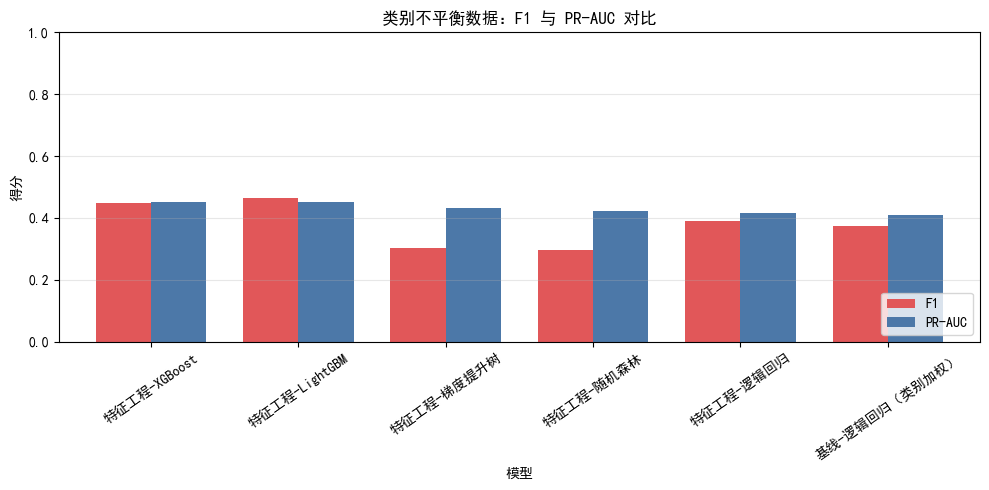

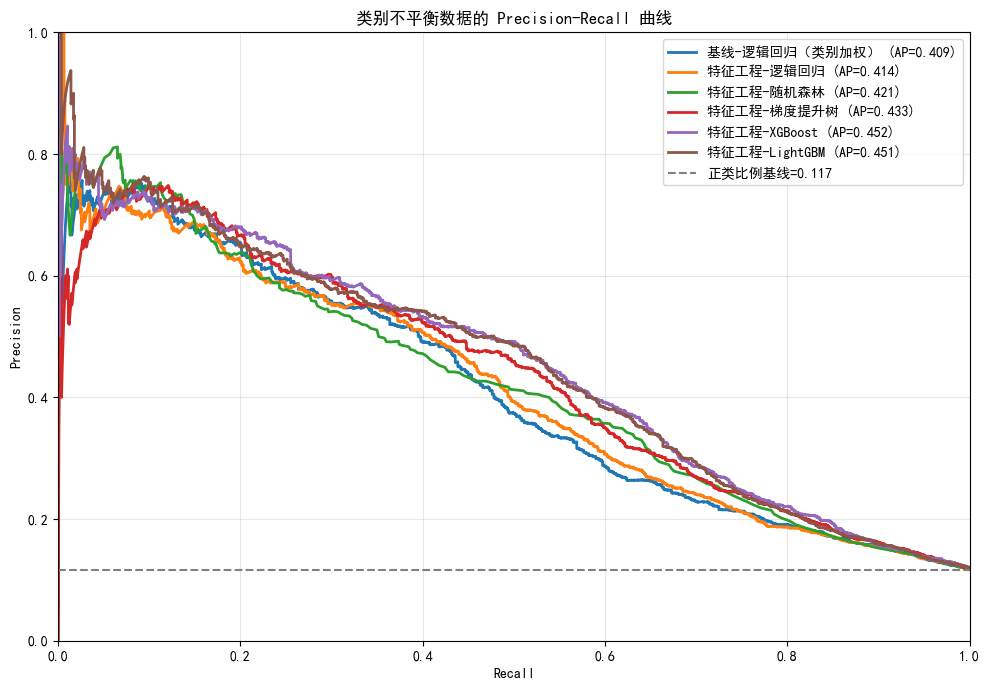


按 PR-AUC 选择的唯一最优模型：特征工程-XGBoost


In [12]:
# 汇总第二部分已经完成的模型评估结果，不重复训练
comparison_df = pd.DataFrame(model_results).sort_values(
    by='PR-AUC', ascending=False
).reset_index(drop=True)

comparison_columns = ['模型', 'F1', 'PR-AUC', 'CV F1均值', 'CV PR-AUC均值']
print('模型效果对比（仅关注 F1 与 PR-AUC）：')
display(comparison_df[comparison_columns].round(4))

focus_metrics = ['F1', 'PR-AUC']
comparison_df.set_index('模型')[focus_metrics].plot(
    kind='bar',
    figsize=(10, 5),
    ylim=(0, 1),
    rot=35,
    width=0.75,
    color=['#E15759', '#4C78A8']
)
plt.title('类别不平衡数据：F1 与 PR-AUC 对比')
plt.ylabel('得分')
plt.xlabel('模型')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# PR 曲线：越靠右上越好，虚线为正类比例基线
plt.figure(figsize=(10, 7))
for name, (y_true_curve, y_prob_curve) in test_probabilities.items():
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_true_curve, y_prob_curve
    )
    ap_score = average_precision_score(y_true_curve, y_prob_curve)
    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=2,
        label=f'{name} (AP={ap_score:.3f})'
    )

positive_rate = y_test.mean()
plt.axhline(
    positive_rate,
    color='gray',
    linestyle='--',
    label=f'正类比例基线={positive_rate:.3f}'
)
plt.title('类别不平衡数据的 Precision-Recall 曲线')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

best_model_name = comparison_df[
    comparison_df['模型'].str.startswith('特征工程-')
].iloc[0]['模型']
print(f'\n按 PR-AUC 选择的唯一最优模型：{best_model_name}')

# 4. 最优模型超参数优化与效果提升

根据第三部分测试集的 PR-AUC 选择最优模型，使用训练集上的 5 折交叉验证进行网格搜索，避免使用测试集调参。

仅对最优模型进行网格搜索：特征工程-XGBoost
最优参数：
{'learning_rate': 0.03, 'max_depth': 5, 'min_child_weight': 3, 'n_estimators': 400, 'scale_pos_weight': np.float64(7.548333727251241)}
3 折交叉验证最佳 PR-AUC：0.4407

调参前后 F1 与 PR-AUC：


,模型,F1,PR-AUC
0,特征工程-XGBoost,0.4475,0.4518
1,特征工程-XGBoost-调参后,0.4502,0.4540



F1 与 PR-AUC 提升量：


,F1,PR-AUC
提升量,0.002752,0.002135


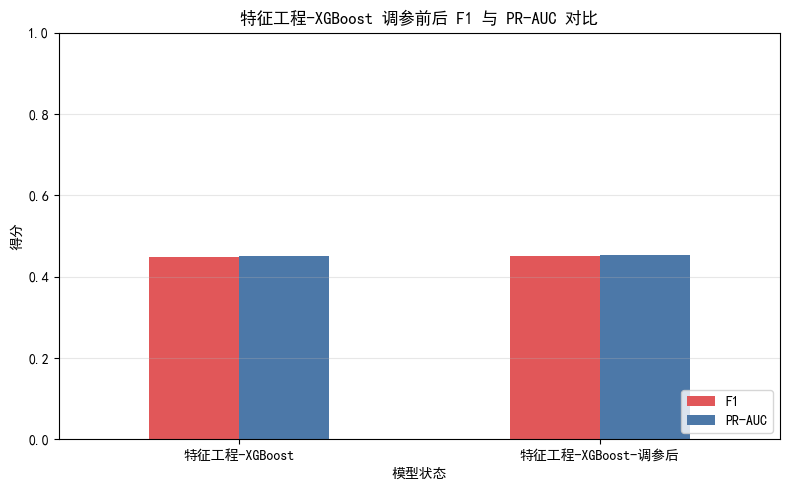

In [13]:
# 只对第三部分 PR-AUC 最优的一个模型进行网格搜索
best_estimator = fitted_models[best_model_name]

if best_model_name == '特征工程-逻辑回归':
    param_grid = {
        'logisticregression__C': [0.03, 0.1, 0.3, 1],
        'logisticregression__class_weight': ['balanced']
    }
elif best_model_name == '特征工程-随机森林':
    param_grid = {
        'n_estimators': [300, 500],
        'max_depth': [None, 12],
        'min_samples_leaf': [1, 5],
        'class_weight': ['balanced', 'balanced_subsample']
    }
elif best_model_name == '特征工程-梯度提升树':
    param_grid = {
        'n_estimators': [150, 300],
        'learning_rate': [0.03, 0.08],
        'max_depth': [2, 3],
        'min_samples_leaf': [1, 5]
    }
elif best_model_name == '特征工程-XGBoost':
    param_grid = {
        'n_estimators': [250, 400],
        'learning_rate': [0.03, 0.08],
        'max_depth': [3, 5],
        'min_child_weight': [3, 8],
        'scale_pos_weight': [positive_weight * 0.85, positive_weight, positive_weight * 1.15]
    }
elif best_model_name == '特征工程-LightGBM':
    param_grid = {
        'n_estimators': [200, 350],
        'learning_rate': [0.03, 0.08],
        'num_leaves': [15, 31],
        'min_child_samples': [20, 50]
    }
else:
    raise ValueError(f'未配置调参网格：{best_model_name}')

print(f'仅对最优模型进行网格搜索：{best_model_name}')
grid_search = GridSearchCV(
    estimator=best_estimator,
    param_grid=param_grid,
    scoring='average_precision',
    cv=3,
    n_jobs=-1,
    pre_dispatch='2*n_jobs',
    refit=True,
    return_train_score=False
)
grid_search.fit(X_train, y_train)

best_tuned_estimator = grid_search.best_estimator_
tuned_prob = best_tuned_estimator.predict_proba(X_test)[:, 1]
tuned_pred = best_tuned_estimator.predict(X_test)
tuned_results = {
    '模型': f'{best_model_name}-调参后',
    'F1': f1_score(y_test, tuned_pred, zero_division=0),
    'PR-AUC': average_precision_score(y_test, tuned_prob)
}

test_probabilities[tuned_results['模型']] = (y_test, tuned_prob)
before_tuning = comparison_df.loc[
    comparison_df['模型'] == best_model_name,
    ['模型', 'F1', 'PR-AUC']
].copy()
after_tuning = pd.DataFrame([tuned_results])
tuning_comparison = pd.concat([before_tuning, after_tuning], ignore_index=True)

print('最优参数：')
print(grid_search.best_params_)
print(f'3 折交叉验证最佳 PR-AUC：{grid_search.best_score_:.4f}')
print('\n调参前后 F1 与 PR-AUC：')
display(tuning_comparison.round(4))

metric_improvement = (
    after_tuning.iloc[0][focus_metrics] - before_tuning.iloc[0][focus_metrics].to_numpy()
)
print('\nF1 与 PR-AUC 提升量：')
display(metric_improvement.to_frame('提升量').T.round(4))

tuning_comparison.set_index('模型')[focus_metrics].plot(
    kind='bar',
    figsize=(8, 5),
    ylim=(0, 1),
    rot=0,
    color=['#E15759', '#4C78A8']
)
plt.title(f'{best_model_name} 调参前后 F1 与 PR-AUC 对比')
plt.ylabel('得分')
plt.xlabel('模型状态')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()